In [1604]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
import scipy.cluster.hierarchy as sch
from sklearn.metrics import davies_bouldin_score

In [1605]:
df = pd.read_csv('energydata_complete.csv')

In [1606]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [1607]:
print("Dataset shape:", df.shape)

Dataset shape: (19735, 29)


In [1608]:
print("\nDataset information:")


Dataset information:


In [1609]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [1610]:
print("\nColumn names:")


Column names:


In [1611]:
print(df.columns)

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='str')


In [1612]:
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [1613]:
df.isnull().sum()

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [1614]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

(array([3.0940e+03, 1.0415e+04, 2.7290e+03, 1.1990e+03, 2.3800e+02,
        2.8600e+02, 2.4300e+02, 3.2700e+02, 2.6900e+02, 1.8500e+02,
        2.1000e+02, 9.8000e+01, 1.0200e+02, 5.2000e+01, 5.8000e+01,
        4.3000e+01, 4.8000e+01, 3.9000e+01, 2.1000e+01, 3.3000e+01,
        1.5000e+01, 1.4000e+01, 6.0000e+00, 4.0000e+00, 4.0000e+00,
        1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00]),
 array([  10.        ,   45.66666667,   81.33333333,  117.        ,
         152.66666667,  188.33333333,  224.        ,  259.66666667,
         295.33333333,  331.        ,  366.66666667,  402.33333333,
         438.        ,  473.66666667,  509.33333333,  545.        ,
         580.66666667,  616.33333333,  652.        ,  687.66666667,
         723.33333333,  759.        ,  794.66666667,  830.33333333,
         866.        ,  901.66666667,  937.33333333,  973.        ,
        1008.66666667, 1044.33333333, 1080.        ]),
 <BarContainer object of 30 artists>)

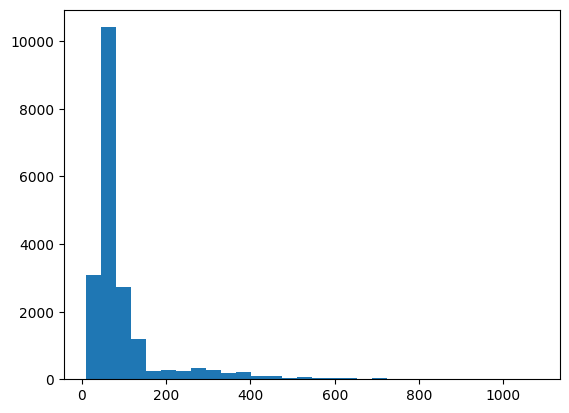

In [1615]:
plt.hist(df['Appliances'], bins=30)

Text(0, 0.5, 'Frequency')

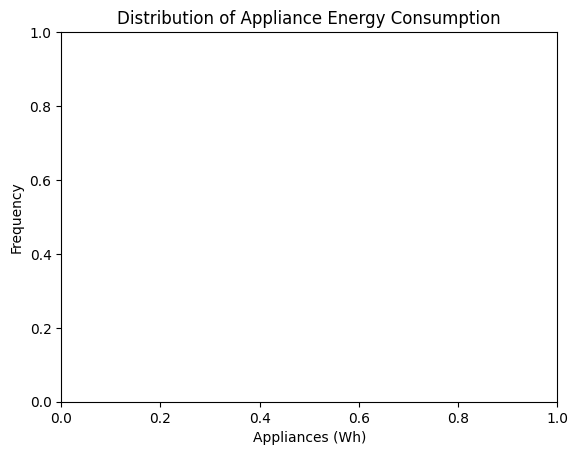

In [1616]:
plt.title('Distribution of Appliance Energy Consumption')
plt.xlabel('Appliances (Wh)')
plt.ylabel('Frequency')

In [1617]:
plt.show()

In [1618]:
features = ['Appliances', 'T1', 'RH_1', 'T_out']

In [1619]:
df[features].corr()

,Appliances,T1,RH_1,T_out
Appliances,1.000000,0.055447,0.086031,0.099155
T1,0.055447,1.000000,0.164006,0.682846
RH_1,0.086031,0.164006,1.000000,0.340767
T_out,0.099155,0.682846,0.340767,1.000000


In [1620]:
X = df[features]

In [1621]:
X.head()

,Appliances,T1,RH_1,T_out
0,60,19.89,47.596667,6.600000
1,60,19.89,46.693333,6.483333
2,50,19.89,46.300000,6.366667
3,50,19.89,46.066667,6.250000
4,60,19.89,46.333333,6.133333


In [1622]:
scaler = StandardScaler()

In [1623]:
X_scaled = scaler.fit_transform(X)

In [1624]:
print(X_scaled[:5])

[[-0.36767572 -1.11864475  1.84382063 -0.15264674]
 [-0.36767572 -1.11864475  1.61680671 -0.17458781]
 [-0.46521548 -1.11864475  1.51795932 -0.19652887]
 [-0.46521548 -1.11864475  1.45932104 -0.21846994]
 [-0.36767572 -1.11864475  1.52633622 -0.24041101]]


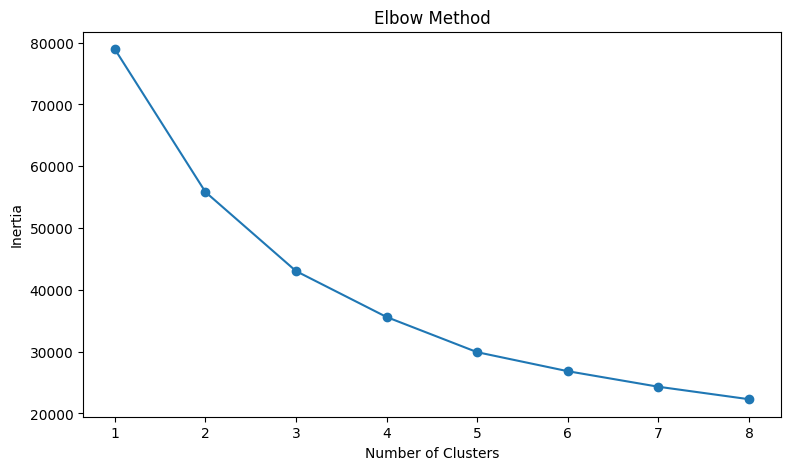

In [1625]:
sse = []

for k in range(1, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    sse.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(range(1, 9), sse, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.show()

In [1626]:
X_small = X_scaled[:2000]

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_small)

    score = silhouette_score(X_small, labels)
    print("Clusters:", k, "Silhouette:", score)

Clusters: 2 Silhouette: 0.4901595580291299
Clusters: 3 Silhouette: 0.3340033801489056
Clusters: 4 Silhouette: 0.3755262057814722
Clusters: 5 Silhouette: 0.35900414101363237
Clusters: 6 Silhouette: 0.36144099617099684


In [1627]:
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

In [1628]:
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

In [1629]:
df['KMeans_Cluster'].value_counts()

KMeans_Cluster
0    11380
1     6844
2     1511
Name: count, dtype: int64

In [1630]:
cluster_summary = df.groupby('KMeans_Cluster')[features].mean()

In [1631]:
print(cluster_summary)

                Appliances         T1       RH_1      T_out
KMeans_Cluster                                             
0                67.004394  20.866653  38.946854   4.300327
1                81.937463  23.094969  42.268023  12.541258
2               400.211780  21.482462  41.051229   7.610269


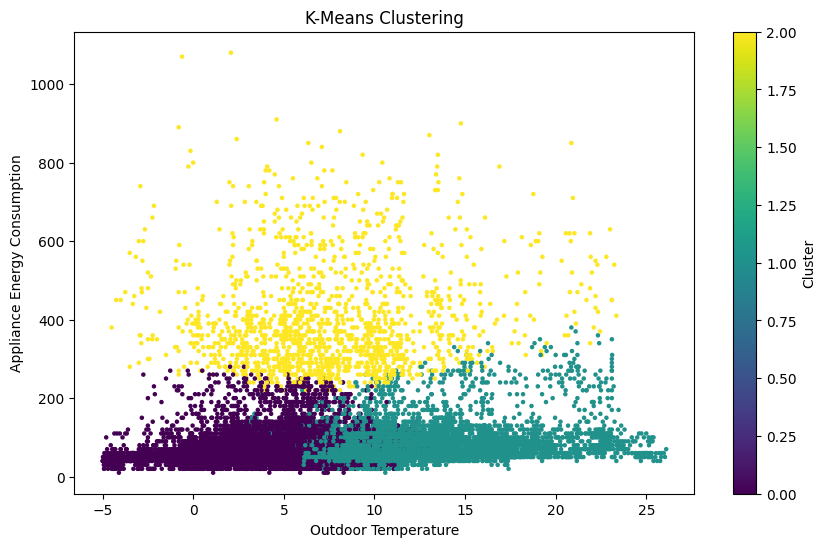

In [1632]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['T_out'],
    df['Appliances'],
    c=df['KMeans_Cluster'],
    cmap='viridis',
    s=5
)

plt.title('K-Means Clustering')
plt.xlabel('Outdoor Temperature')
plt.ylabel('Appliance Energy Consumption')

plt.colorbar(label='Cluster')

plt.show()

In [1633]:
# Hierarchical clustering

In [1634]:
ac = AgglomerativeClustering(n_clusters=best_k, linkage='average')

ac_clusters = ac.fit_predict(X_small)

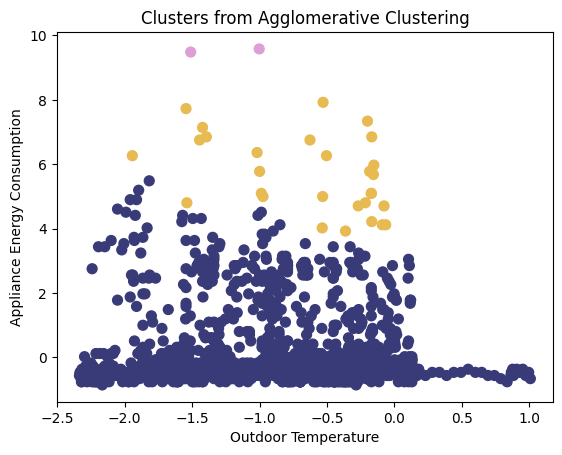

In [1635]:
plt.title("Clusters from Agglomerative Clustering")

plt.scatter(X_small[:, 3], X_small[:, 0], c=ac_clusters, s=50, cmap='tab20b')

plt.xlabel("Outdoor Temperature")

plt.ylabel("Appliance Energy Consumption")

plt.show()

In [1636]:
print(pd.Series(ac_clusters).value_counts())

0    1969
1      29
2       2
Name: count, dtype: int64


In [1637]:
# DBSCAN Clustering

In [1638]:
db_param_options = [
    [0.3, 5],
    [0.5, 5],
    [0.7, 5],
    [0.5, 7],
    [0.7, 7],
    [1.0, 5]
]

for ep, min_sample in db_param_options:

    db = DBSCAN(eps=ep, min_samples=min_sample)

    db_clusters = db.fit_predict(X_small)

    print("Eps:", ep, "Min Samples:", min_sample)

    print("Clusters:", len(set(db_clusters)) - (1 if -1 in db_clusters else 0))

    print("Noise:", (db_clusters == -1).sum())

Eps: 0.3 Min Samples: 5
Clusters: 21
Noise: 344
Eps: 0.5 Min Samples: 5
Clusters: 14
Noise: 165
Eps: 0.7 Min Samples: 5
Clusters: 4
Noise: 67
Eps: 0.5 Min Samples: 7
Clusters: 8
Noise: 242
Eps: 0.7 Min Samples: 7
Clusters: 2
Noise: 91
Eps: 1.0 Min Samples: 5
Clusters: 1
Noise: 18


In [1639]:
db = DBSCAN(eps=0.5, min_samples=5)

db_clusters = db.fit_predict(X_small)

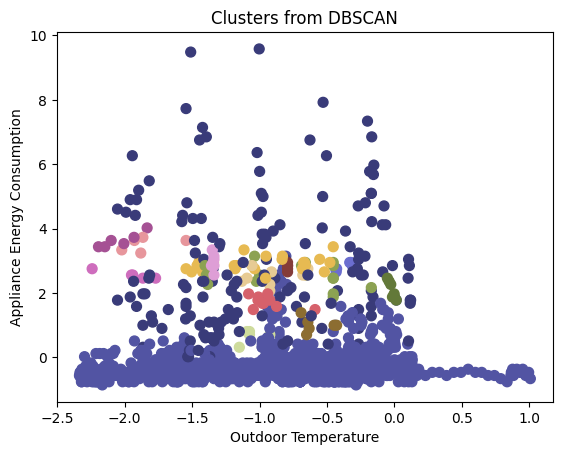

In [1640]:
plt.title("Clusters from DBSCAN")

plt.scatter(X_small[:, 3], X_small[:, 0], c=db_clusters, s=50, cmap='tab20b')

plt.xlabel("Outdoor Temperature")

plt.ylabel("Appliance Energy Consumption")

plt.show()

In [1641]:
print(pd.Series(db_clusters).value_counts())

 0     1722
-1      165
 6       25
 3       17
 9       10
 7        9
 2        7
 13       7
 1        6
 5        6
 11       6
 4        5
 8        5
 10       5
 12       5
Name: count, dtype: int64


In [1642]:
# Clustering comparison

In [1643]:
km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_clusters = km.fit_predict(X_small)

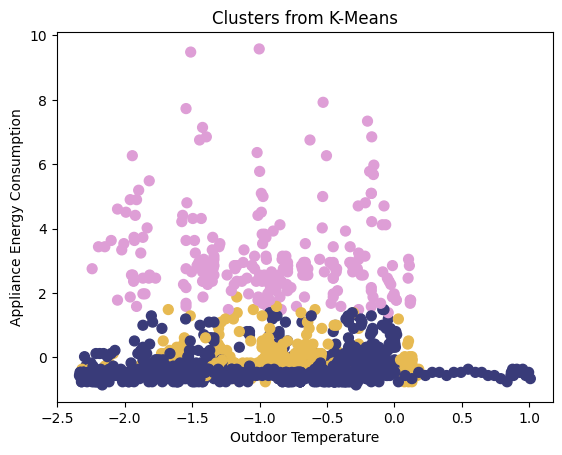

In [1644]:
plt.title("Clusters from K-Means")

plt.scatter(X_small[:, 3], X_small[:, 0], c=km_clusters, s=50, cmap='tab20b')

plt.xlabel("Outdoor Temperature")

plt.ylabel("Appliance Energy Consumption")

plt.show()

In [1645]:
print("Silhouette Scores:\n")

print("K-Means:", silhouette_score(X_small, km_clusters))

print("Agglomerative:", silhouette_score(X_small, ac_clusters))

Silhouette Scores:

K-Means: 0.3340033801489056
Agglomerative: 0.598037301791222


In [1646]:
if 1 < len(set(db_clusters)) < len(X_small):

    print("DBSCAN:", silhouette_score(X_small, db_clusters))

else:

    print("DBSCAN: Silhouette Score cannot be calculated")

DBSCAN: -0.10335607585384647


In [1647]:
# Hierarchical clustering dendrogram

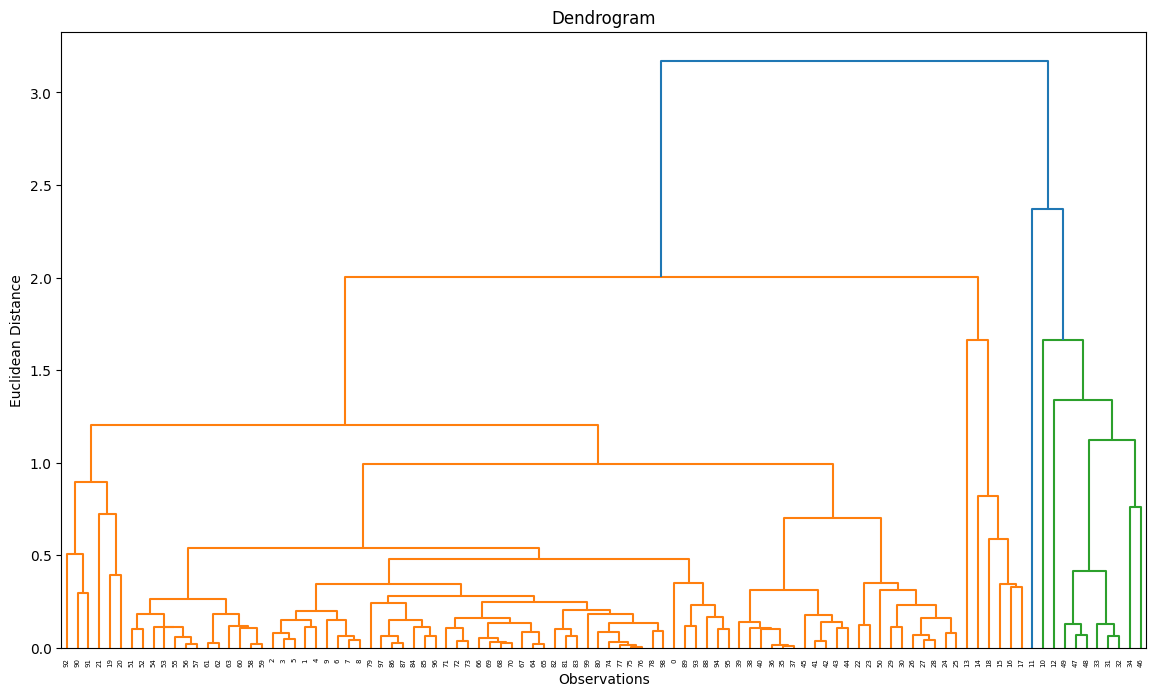

In [1648]:
plt.figure(figsize=(14, 8))

dendrogram = sch.dendrogram(sch.linkage(X_small[:100], method='average'))

plt.title('Dendrogram')

plt.xlabel('Observations')

plt.ylabel('Euclidean Distance')

plt.show()

In [1649]:
# Davies bouldin index

In [1650]:
dbi_kmeans = davies_bouldin_score(X_small, km_clusters)

print("K-Means Davies-Bouldin Index:", dbi_kmeans)

K-Means Davies-Bouldin Index: 1.0635546354979202


In [1651]:
dbi_agglomerative = davies_bouldin_score(X_small, ac_clusters)

print("Agglomerative Davies-Bouldin Index:", dbi_agglomerative)

Agglomerative Davies-Bouldin Index: 0.6696619548472341


In [1652]:
db_mask = db_clusters != -1

if len(set(db_clusters[db_mask])) > 1:

    dbi_dbscan = davies_bouldin_score(
        X_small[db_mask],
        db_clusters[db_mask]
    )

    print("DBSCAN Davies-Bouldin Index:", dbi_dbscan)

else:

    dbi_dbscan = np.nan

    print("DBSCAN Davies-Bouldin Index cannot be calculated")

DBSCAN Davies-Bouldin Index: 0.7555290487876152


In [1653]:
# Clustering evaluation

In [1654]:
silhouette_kmeans = silhouette_score(X_small, km_clusters)

silhouette_agglomerative = silhouette_score(X_small, ac_clusters)

if len(set(db_clusters[db_mask])) > 1:

    silhouette_dbscan = silhouette_score(
        X_small[db_mask],
        db_clusters[db_mask]
    )

else:

    silhouette_dbscan = np.nan

In [1655]:
clustering_results = pd.DataFrame({
    'Algorithm': ['K-Means', 'Agglomerative', 'DBSCAN'],
    'Silhouette Score': [
        silhouette_kmeans,
        silhouette_agglomerative,
        silhouette_dbscan
    ],
    'Davies-Bouldin Index': [
        dbi_kmeans,
        dbi_agglomerative,
        dbi_dbscan
    ]
})

print(clustering_results)

       Algorithm  Silhouette Score  Davies-Bouldin Index
0        K-Means          0.334003              1.063555
1  Agglomerative          0.598037              0.669662
2         DBSCAN         -0.064078              0.755529


In [1656]:
# Time series analysis

In [1657]:
df['date'] = pd.to_datetime(df['date'])

df[['date', 'Appliances']].head()

,date,Appliances
0,2016-01-11 17:00:00,60
1,2016-01-11 17:10:00,60
2,2016-01-11 17:20:00,50
3,2016-01-11 17:30:00,50
4,2016-01-11 17:40:00,60


In [1658]:
daily = df.iloc[::144][['date', 'Appliances']].copy()

daily.head()

,date,Appliances
0,2016-01-11 17:00:00,60
144,2016-01-12 17:00:00,60
288,2016-01-13 17:00:00,90
432,2016-01-14 17:00:00,910
576,2016-01-15 17:00:00,90


In [1659]:
daily = daily.set_index('date')

In [1660]:
daily.head()

,Appliances
date,
2016-01-11 17:00:00,60
2016-01-12 17:00:00,60
2016-01-13 17:00:00,90
2016-01-14 17:00:00,910
2016-01-15 17:00:00,90


In [1661]:
print(daily.shape)

(138, 1)


In [1662]:
print(daily.isnull().sum())

Appliances    0
dtype: int64


In [1663]:
print(daily.describe())

       Appliances
count  138.000000
mean   128.115942
std    125.165880
min     20.000000
25%     60.000000
50%     90.000000
75%    127.500000
max    910.000000


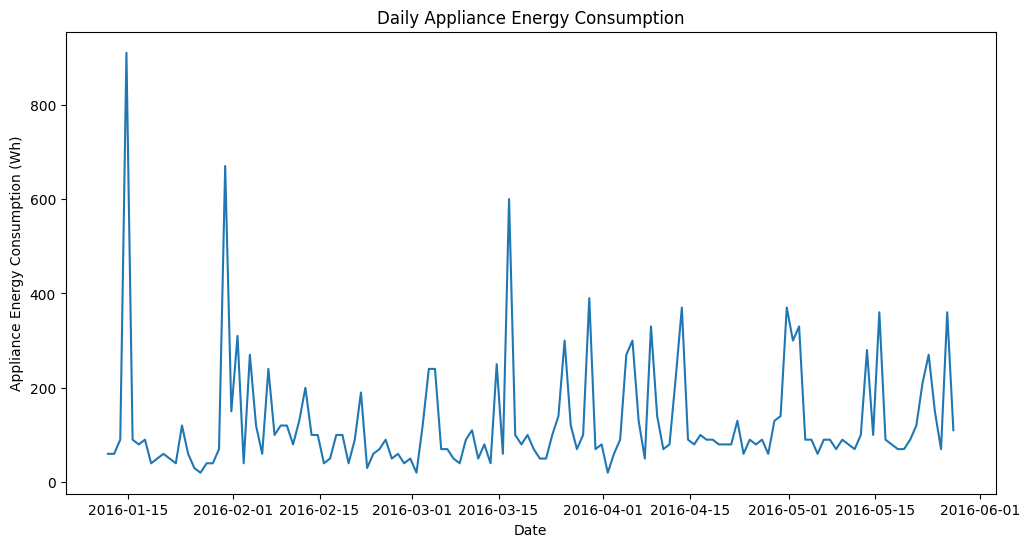

In [1664]:
plt.figure(figsize=(12, 6))

plt.plot(daily.index, daily['Appliances'])

plt.title('Daily Appliance Energy Consumption')

plt.xlabel('Date')

plt.ylabel('Appliance Energy Consumption (Wh)')

plt.show()

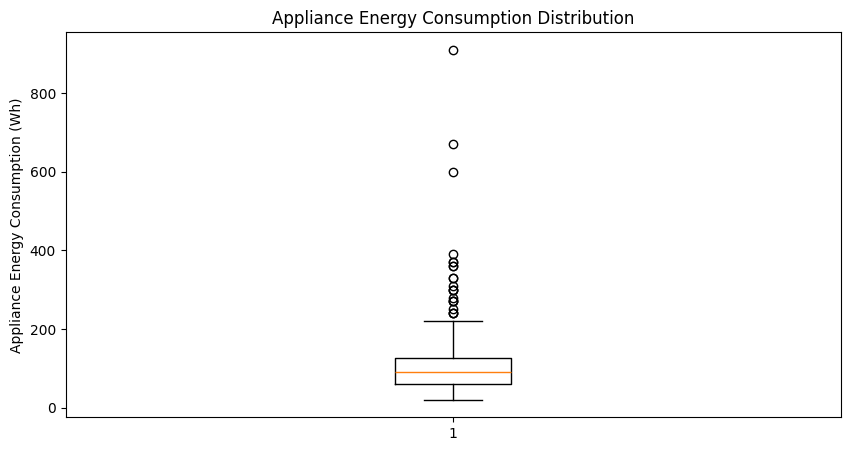

In [1665]:
plt.figure(figsize=(10, 5))

plt.boxplot(daily['Appliances'])

plt.title('Appliance Energy Consumption Distribution')

plt.ylabel('Appliance Energy Consumption (Wh)')

plt.show()